Importing Required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import zipfile

from collections import Counter

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print("All libraries imported successfully!")

All libraries imported successfully!


Uploading Instagram Dataset

In [3]:
from google.colab import files

uploaded = files.upload()

Saving archive (3).zip to archive (3).zip


Extracting zip file data set

In [4]:
zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/instagram_data')

print("Dataset extracted successfully!")

Dataset extracted successfully!


Checking dataset files

In [5]:
for root, dirs, files_list in os.walk('/content/instagram_data'):
    for file in files_list:
        print(file)

follows.csv
likes.csv
photos.csv
tags.csv
photo_tags.csv
comments.csv
users.csv


Load and understand dataset

In [6]:
csv_files = []

for root, dirs, files_list in os.walk('/content/instagram_data'):
    for file in files_list:
        if file.endswith('.csv'):
            csv_files.append(os.path.join(root, file))

print("Total CSV files:", len(csv_files))

for file in csv_files:
    print(file)

Total CSV files: 7
/content/instagram_data/follows.csv
/content/instagram_data/likes.csv
/content/instagram_data/photos.csv
/content/instagram_data/tags.csv
/content/instagram_data/photo_tags.csv
/content/instagram_data/comments.csv
/content/instagram_data/users.csv


In [7]:
dataframes = {}

for file in csv_files:
    name = os.path.basename(file).replace('.csv', '')
    dataframes[name] = pd.read_csv(file)

    print("\nFile:", name)
    print("Shape:", dataframes[name].shape)
    print("Columns:", dataframes[name].columns.tolist())


File: follows
Shape: (7623, 5)
Columns: ['follower', 'followee ', 'created time', 'is follower active', 'followee Acc status']

File: likes
Shape: (8782, 5)
Columns: ['user ', 'photo', 'created time', 'following or not', 'like type']

File: photos
Shape: (257, 6)
Columns: ['id', 'image link', 'user ID', 'created dat', 'Insta filter used', 'photo type']

File: tags
Shape: (21, 4)
Columns: ['id', 'tag text', 'created time', 'location']

File: photo_tags
Shape: (501, 3)
Columns: ['photo', 'tag ID', 'user id']

File: comments
Shape: (7488, 8)
Columns: ['id', 'comment', 'User  id', 'Photo id', 'created Timestamp', 'posted date', 'emoji used', 'Hashtags used count']

File: users
Shape: (100, 6)
Columns: ['id', 'name', 'created time', 'private/public', 'post count', 'Verified status']


 Data Inspection : In this section, we inspect all datasets to understand
their structure, data types, missing values and duplicate records.

 Display first 5 rows of each dataset

In [8]:
for name, df in dataframes.items():

    print("\n==========", name.upper(), "==========")

    display(df.head())

    print("Shape:", df.shape)

    print("Data Types:")
    print(df.dtypes)

    print("Missing Values:")
    print(df.isnull().sum())

    print("Duplicate Rows:", df.duplicated().sum())


========== FOLLOWS ==========


,follower,followee,created time,is follower active,followee Acc status
0,2,1,13-04-2023 08:04,1,Private
1,2,3,13-04-2023 08:04,0,private
2,2,4,13-04-2023 08:04,0,public
3,2,5,13-04-2023 08:04,0,private
4,2,6,13-04-2023 08:04,1,private


Shape: (7623, 5)
Data Types:
follower                int64
followee                int64
created time           object
is follower active      int64
followee Acc status    object
dtype: object
Missing Values:
follower               0
followee               0
created time           0
is follower active     0
followee Acc status    0
dtype: int64
Duplicate Rows: 0

========== LIKES ==========


,user,photo,created time,following or not,like type
0,2,1,13-04-2023 08:04,yes,heart emoji
1,2,4,13-04-2023 08:04,no,thumbs up
2,2,8,13-04-2023 08:04,yes,laughing
3,2,9,13-04-2023 08:04,no,fire
4,2,10,13-04-2023 08:04,yes,clap


Shape: (8782, 5)
Data Types:
user                 int64
photo                int64
created time        object
following or not    object
like type           object
dtype: object
Missing Values:
user                0
photo               0
created time        0
following or not    0
like type           0
dtype: int64
Duplicate Rows: 0

========== PHOTOS ==========


,id,image link,user ID,created dat,Insta filter used,photo type
0,1,http://elijah.biz,1,13-04-2023 08:04,yes,photo
1,2,https://shanon.org,1,13-04-2023 08:04,no,photo
2,3,http://vicky.biz,1,13-04-2023 08:04,no,photo
3,4,http://oleta.net,1,13-04-2023 08:04,no,photo
4,5,https://jennings.biz,1,13-04-2023 08:04,yes,photo


... (5 outputs left out)

,id,comment,User id,Photo id,created Timestamp,posted date,emoji used,Hashtags used count
0,1,unde at dolorem,2,1,13-04-2023 08:04,April 14,yes,1
1,2,quae ea ducimus,3,1,13-04-2023 08:04,April 14,no,2
2,3,alias a voluptatum,5,1,13-04-2023 08:04,April 14,no,4
3,4,facere suscipit sunt,14,1,13-04-2023 08:04,April 14,yes,2
4,5,totam eligendi quaerat,17,1,13-04-2023 08:04,April 14,yes,1


Shape: (7488, 8)
Data Types:
id                      int64
comment                object
User  id                int64
Photo id                int64
created Timestamp      object
posted date            object
emoji used             object
Hashtags used count     int64
dtype: object
Missing Values:
id                     0
comment                0
User  id               0
Photo id               0
created Timestamp      0
posted date            0
emoji used             0
Hashtags used count    0
dtype: int64
Duplicate Rows: 0

========== USERS ==========


,id,name,created time,private/public,post count,Verified status
0,1,Kenton_Kirlin,16-02-2017 18:22,yes,11,no
1,2,Andre_Purdy85,02-04-2017 17:11,no,7,no
2,3,Harley_Lind18,21-02-2017 11:12,no,2,no
3,4,Arely_Bogan63,13-08-2016 01:28,yes,1,no
4,5,Aniya_Hackett,07-12-2016 01:04,yes,3,no


Shape: (100, 6)
Data Types:
id                  int64
name               object
created time       object
private/public     object
post count          int64
Verified status    object
dtype: object
Missing Values:
id                 0
name               0
created time       0
private/public     0
post count         0
Verified status    0
dtype: int64
Duplicate Rows: 0


Checking Date and Time Columns

In [9]:
date_columns = {
    'photos': ['created dat'],
    'likes': ['created time'],
    'comments': ['created Timestamp', 'posted date'],
    'follows': ['created time'],
    'tags': ['created time'],
    'users': ['created time']
}

for table, columns in date_columns.items():

    df = dataframes[table]

    print("\n", table.upper())

    for col in columns:

        if col in df.columns:
            print("\nColumn:", col)
            print(df[col].head())
            print("Data Type:", df[col].dtype)


 PHOTOS

Column: created dat
0    13-04-2023 08:04
1    13-04-2023 08:04
2    13-04-2023 08:04
3    13-04-2023 08:04
4    13-04-2023 08:04
Name: created dat, dtype: object
Data Type: object

 LIKES

Column: created time
0    13-04-2023 08:04
1    13-04-2023 08:04
2    13-04-2023 08:04
3    13-04-2023 08:04
4    13-04-2023 08:04
Name: created time, dtype: object
Data Type: object

 COMMENTS

Column: created Timestamp
0    13-04-2023 08:04
1    13-04-2023 08:04
2    13-04-2023 08:04
3    13-04-2023 08:04
4    13-04-2023 08:04
Name: created Timestamp, dtype: object
Data Type: object

Column: posted date
0    April 14
1    April 14
2    April 14
3    April 14
4    April 14
Name: posted date, dtype: object
Data Type: object

 FOLLOWS

Column: created time
0    13-04-2023 08:04
1    13-04-2023 08:04
2    13-04-2023 08:04
3    13-04-2023 08:04
4    13-04-2023 08:04
Name: created time, dtype: object
Data Type: object

 TAGS

Column: created time
0    13-04-2023 08:04
1    13-04-2023 08:04
2  

 Check relationships

In [10]:
print("Photos:")
print(dataframes['photos'][['id', 'user ID', 'created dat', 'photo type']].head())

print("\nLikes:")
print(dataframes['likes'].head())

print("\nComments:")
print(dataframes['comments'].head())

print("\nPhoto Tags:")
print(dataframes['photo_tags'].head())

print("\nTags:")
print(dataframes['tags'].head())

print("\nFollows:")
print(dataframes['follows'].head())

Photos:
   id  user ID       created dat photo type
0   1        1  13-04-2023 08:04      photo
1   2        1  13-04-2023 08:04      photo
2   3        1  13-04-2023 08:04      photo
3   4        1  13-04-2023 08:04      photo
4   5        1  13-04-2023 08:04      photo

Likes:
   user   photo      created time following or not    like type
0      2      1  13-04-2023 08:04              yes  heart emoji
1      2      4  13-04-2023 08:04               no    thumbs up
2      2      8  13-04-2023 08:04              yes     laughing
3      2      9  13-04-2023 08:04               no         fire
4      2     10  13-04-2023 08:04              yes         clap

Comments:
   id                 comment  User  id  Photo id created Timestamp  \
0   1         unde at dolorem         2         1  13-04-2023 08:04   
1   2         quae ea ducimus         3         1  13-04-2023 08:04   
2   3      alias a voluptatum         5         1  13-04-2023 08:04   
3   4    facere suscipit sunt        14  

Data Cleaning and Preprocessing :

In this section, we clean the Instagram datasets,
convert date columns into datetime format,
and check missing values and duplicate records.

Create copies of all datasets

In [11]:
photos = dataframes['photos'].copy()
likes = dataframes['likes'].copy()
comments = dataframes['comments'].copy()
users = dataframes['users'].copy()
follows = dataframes['follows'].copy()
tags = dataframes['tags'].copy()
photo_tags = dataframes['photo_tags'].copy()

print("All datasets copied successfully!")

All datasets copied successfully!


Convert date columns into datetime format

In [12]:
photos['created dat'] = pd.to_datetime(
    photos['created dat'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

likes['created time'] = pd.to_datetime(
    likes['created time'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

comments['created Timestamp'] = pd.to_datetime(
    comments['created Timestamp'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

follows['created time'] = pd.to_datetime(
    follows['created time'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

tags['created time'] = pd.to_datetime(
    tags['created time'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

users['created time'] = pd.to_datetime(
    users['created time'],
    format='%d-%m-%Y %H:%M',
    errors='coerce'
)

print("Date conversion completed!")

Date conversion completed!


Checking date conversion

In [13]:
date_datasets = {
    'Photos': photos['created dat'],
    'Likes': likes['created time'],
    'Comments': comments['created Timestamp'],
    'Follows': follows['created time'],
    'Tags': tags['created time'],
    'Users': users['created time']
}

for name, column in date_datasets.items():

    print("\n", name)

    print("Unique Dates:", column.nunique())
    print("Missing Dates:", column.isna().sum())
    print("Minimum Date:", column.min())
    print("Maximum Date:", column.max())


 Photos
Unique Dates: 1
Missing Dates: 0
Minimum Date: 2023-04-13 08:04:00
Maximum Date: 2023-04-13 08:04:00

 Likes
Unique Dates: 1
Missing Dates: 0
Minimum Date: 2023-04-13 08:04:00
Maximum Date: 2023-04-13 08:04:00

 Comments
Unique Dates: 1
Missing Dates: 0
Minimum Date: 2023-04-13 08:04:00
Maximum Date: 2023-04-13 08:04:00

 Follows
Unique Dates: 1
Missing Dates: 0
Minimum Date: 2023-04-13 08:04:00
Maximum Date: 2023-04-13 08:04:00

 Tags
Unique Dates: 1
Missing Dates: 0
Minimum Date: 2023-04-13 08:04:00
Maximum Date: 2023-04-13 08:04:00

 Users
Unique Dates: 100
Missing Dates: 0
Minimum Date: 2016-05-06 00:14:00
Maximum Date: 2017-05-04 16:32:00


Clean text columns

In [14]:

for df, columns in [
    (photos, ['photo type', 'Insta filter used']),
    (likes, ['like type', 'following or not']),
    (comments, ['comment', 'emoji used']),
    (tags, ['tag text', 'location']),
    (users, ['name', 'private/public', 'Verified status'])
]:

    for col in columns:
        df[col] = df[col].astype(str).str.strip()

print("Text cleaning completed!")

Text cleaning completed!


Final cleaning check

In [15]:
clean_datasets = {
    'photos': photos,
    'likes': likes,
    'comments': comments,
    'follows': follows,
    'tags': tags,
    'users': users,
    'photo_tags': photo_tags
}

for name, df in clean_datasets.items():

    print("\n", name.upper())

    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("Missing Values:", df.isnull().sum().sum())
    print("Duplicate Rows:", df.duplicated().sum())


 PHOTOS
Rows: 257
Columns: 6
Missing Values: 0
Duplicate Rows: 0

 LIKES
Rows: 8782
Columns: 5
Missing Values: 0
Duplicate Rows: 0

 COMMENTS
Rows: 7488
Columns: 8
Missing Values: 0
Duplicate Rows: 0

 FOLLOWS
Rows: 7623
Columns: 5
Missing Values: 0
Duplicate Rows: 0

 TAGS
Rows: 21
Columns: 4
Missing Values: 0
Duplicate Rows: 0

 USERS
Rows: 100
Columns: 6
Missing Values: 0
Duplicate Rows: 0

 PHOTO_TAGS
Rows: 501
Columns: 3
Missing Values: 0
Duplicate Rows: 0


Engagement Metrics Calculation : In this section, we calculate total likes, comments,
followers and engagement rates for each Instagram post.

These metrics help us identify high-performing posts
and understand audience engagement.

Counting total likes for each photo

In [23]:
likes_per_post = (
    likes.groupby('photo')['user ']
    .count()
    .reset_index(name='total_likes')
)

likes_per_post.rename(columns={'photo': 'id'}, inplace=True)

display(likes_per_post.head())

print("Total posts with likes:", len(likes_per_post))

,id,total_likes
0,1,25
1,2,36
2,3,38
3,4,38
4,5,31


Total posts with likes: 257


Counting total comments for each photo

In [19]:
comments_per_post = (
    comments.groupby('Photo id')['id']
    .count()
    .reset_index(name='total_comments')
)

comments_per_post.rename(columns={'Photo id': 'id'}, inplace=True)

display(comments_per_post.head())

,id,total_comments
0,1,25
1,2,31
2,3,27
3,4,32
4,5,27


Calculate followers per account

In [24]:
total_followers = (
    follows.groupby('followee ')
    .size()
    .reset_index(name='total_followers')
)

active_followers = (
    follows[follows['is follower active'] == 1]
    .groupby('followee')
    .size()
    .reset_index(name='active_followers')
)

display(total_followers.head())
display(active_followers.head())

,followee,total_followers
0,1,77
1,2,76
2,3,76
3,4,76
4,5,76


,followee,active_followers
0,1,43
1,2,42
2,3,42
3,4,42
4,5,41


Merge all datasets

In [26]:
instagram_analysis = photos.merge(
    likes_per_post,
    on='id',
    how='left'
)

instagram_analysis = instagram_analysis.merge(
    comments_per_post,
    on='id',
    how='left'
)

# Add follower information

instagram_analysis = instagram_analysis.merge(
    active_followers,
    left_on='user ID',
    right_on='followee',
    how='left'
)

# Replace missing counts with zero

instagram_analysis['total_likes'] = (
    instagram_analysis['total_likes'].fillna(0)
)

instagram_analysis['total_comments'] = (
    instagram_analysis['total_comments'].fillna(0)
)

instagram_analysis['active_followers'] = (
    instagram_analysis['active_followers'].fillna(0)
)

# Remove unnecessary merge column

instagram_analysis.drop(
    columns=['followee'],
    inplace=True
)

display(instagram_analysis.head())

print("Final Dataset Shape:", instagram_analysis.shape)

,id,image link,user ID,created dat,Insta filter used,photo type,total_likes,total_comments,active_followers
0,1,http://elijah.biz,1,2023-04-13 08:04:00,yes,photo,25,25,43
1,2,https://shanon.org,1,2023-04-13 08:04:00,no,photo,36,31,43
2,3,http://vicky.biz,1,2023-04-13 08:04:00,no,photo,38,27,43
3,4,http://oleta.net,1,2023-04-13 08:04:00,no,photo,38,32,43
4,5,https://jennings.biz,1,2023-04-13 08:04:00,yes,photo,31,27,43


Final Dataset Shape: (257, 9)


Calculate engagement rate

In [35]:
instagram_analysis = instagram_analysis.drop(
    columns=['active_followers', 'likes_per_follower',
             'comments_per_follower', 'engagement_rate'],
    errors='ignore'
)

instagram_analysis = instagram_analysis.merge(
    total_followers,
    left_on='user ID',
    right_on='followee',
    how='left'
)

instagram_analysis['likes_per_follower'] = (
    instagram_analysis['total_likes'] /
    instagram_analysis['total_followers']
)

instagram_analysis['comments_per_follower'] = (
    instagram_analysis['total_comments'] /
    instagram_analysis['total_followers']
)

display(instagram_analysis.head())

,id,image link,user ID,created dat,Insta filter used,photo type,total_likes,total_comments,followee,total_followers,likes_per_follower,comments_per_follower
0,1,http://elijah.biz,1,2023-04-13 08:04:00,yes,photo,25,25,1,77,0.324675,0.324675
1,2,https://shanon.org,1,2023-04-13 08:04:00,no,photo,36,31,1,77,0.467532,0.402597
2,3,http://vicky.biz,1,2023-04-13 08:04:00,no,photo,38,27,1,77,0.493506,0.350649
3,4,http://oleta.net,1,2023-04-13 08:04:00,no,photo,38,32,1,77,0.493506,0.415584
4,5,https://jennings.biz,1,2023-04-13 08:04:00,yes,photo,31,27,1,77,0.402597,0.350649


Finding top 10 engaging posts

In [37]:
top_posts = instagram_analysis.sort_values(
    by='engagement_rate',
    ascending=False
)

display(
    top_posts[
        [
            'id',
            'photo type',
            'total_likes',
            'total_comments',
            'active_followers',
            'engagement_rate'
        ]
    ].head(10)
)

,id,photo type,total_likes,total_comments,total_followers,engagement_rate
12,13,photo,40,39,76,103.947368
144,145,video,48,27,76,98.684211
146,147,photo,41,34,76,98.684211
117,118,photo,39,35,76,97.368421
226,227,photo,39,35,76,97.368421
224,225,video,37,36,76,96.052632
195,196,photo,38,35,76,96.052632
122,123,photo,42,31,76,96.052632
126,127,photo,43,30,76,96.052632
96,97,photo,40,32,76,94.736842


Create engagement visualization

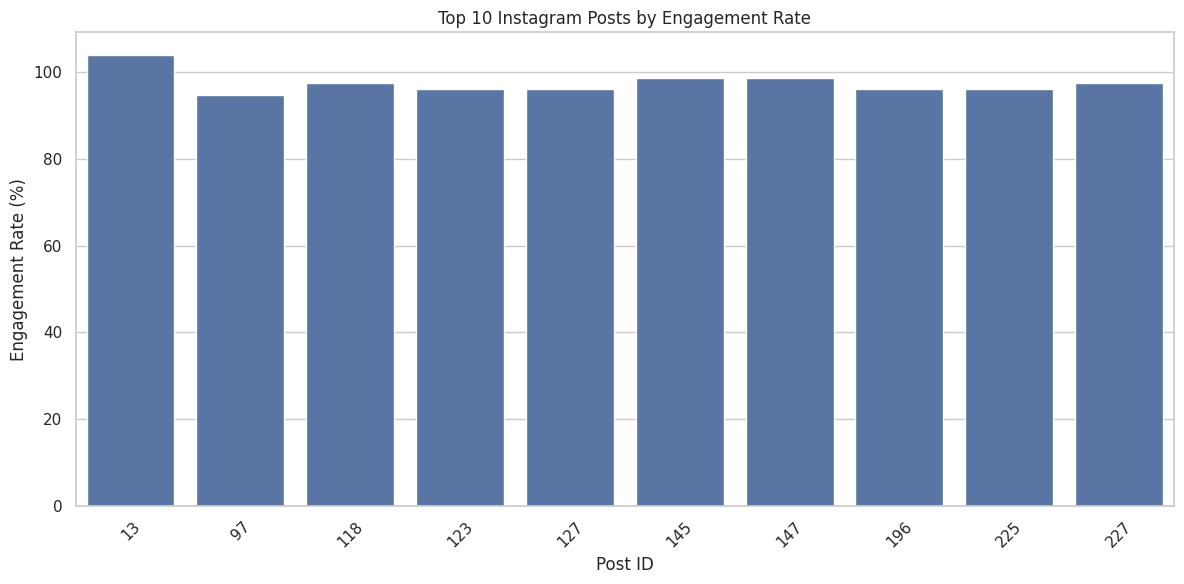

In [38]:
top_10 = top_posts.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10,
    x='id',
    y='engagement_rate'
)

plt.title('Top 10 Instagram Posts by Engagement Rate')
plt.xlabel('Post ID')
plt.ylabel('Engagement Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Content Type Analysis : This section analyzes different Instagram content types
to identify which types generate higher engagement.

In [39]:
print(photos['photo type'].value_counts())

photo type
photo       155
video        52
carousel     50
Name: count, dtype: int64


In [40]:
content_analysis = (
    instagram_analysis.groupby('photo type')
    .agg(
        total_posts=('id', 'count'),
        avg_likes=('total_likes', 'mean'),
        avg_comments=('total_comments', 'mean'),
        avg_engagement=('engagement_rate', 'mean')
    )
    .reset_index()
)

display(content_analysis)

,photo type,total_posts,avg_likes,avg_comments,avg_engagement
0,carousel,50,33.860000,28.680000,81.994532
1,photo,155,34.387097,29.245161,83.377726
2,video,52,33.826923,29.250000,82.689022


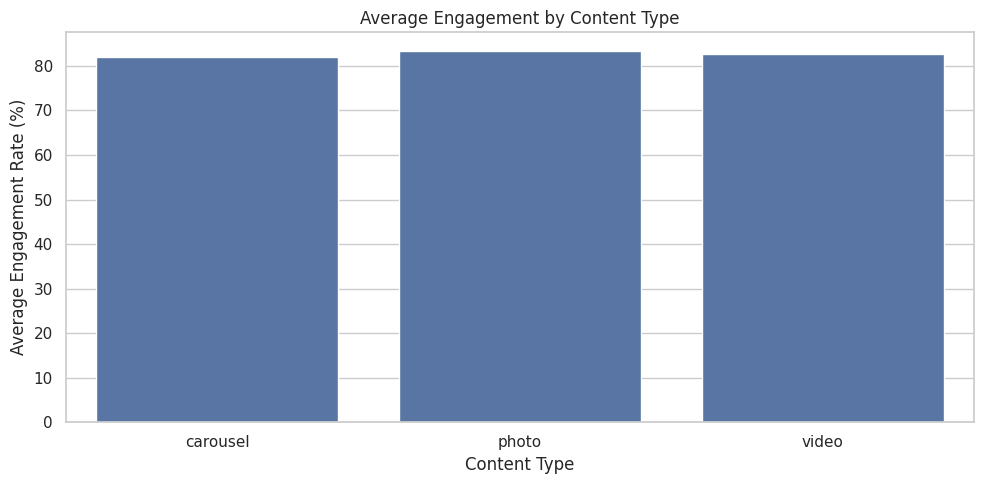

In [41]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=content_analysis,
    x='photo type',
    y='avg_engagement'
)

plt.title('Average Engagement by Content Type')
plt.xlabel('Content Type')
plt.ylabel('Average Engagement Rate (%)')

plt.tight_layout()
plt.show()

Hashtag Analysis : Analyze popular hashtags used in Instagram posts
and their relationship with engagement.

In [42]:
# Connect photos with hashtags

hashtag_data = photo_tags.merge(
    tags,
    left_on='tag ID',
    right_on='id',
    how='left'
)

hashtag_data = hashtag_data.merge(
    instagram_analysis[['id', 'total_likes', 'total_comments']],
    left_on='photo',
    right_on='id',
    how='left'
)

# Calculate hashtag performance

hashtag_analysis = hashtag_data.groupby('tag text').agg(
    total_posts=('photo', 'nunique'),
    avg_likes=('total_likes', 'mean'),
    avg_comments=('total_comments', 'mean')
).reset_index()

hashtag_analysis = hashtag_analysis.sort_values(
    'total_posts', ascending=False
)

display(hashtag_analysis)

,tag text,total_posts,avg_likes,avg_comments
16,smile,59,34.457627,29.237288
0,beach,42,34.476190,28.952381
14,party,39,33.923077,29.512821
9,fun,38,34.236842,28.657895
2,concert,24,34.375000,28.166667
13,lol,24,34.208333,28.791667
7,food,24,33.833333,30.291667
10,hair,23,34.521739,28.347826
11,happy,22,34.590909,28.409091
1,beauty,20,34.950000,30.200000


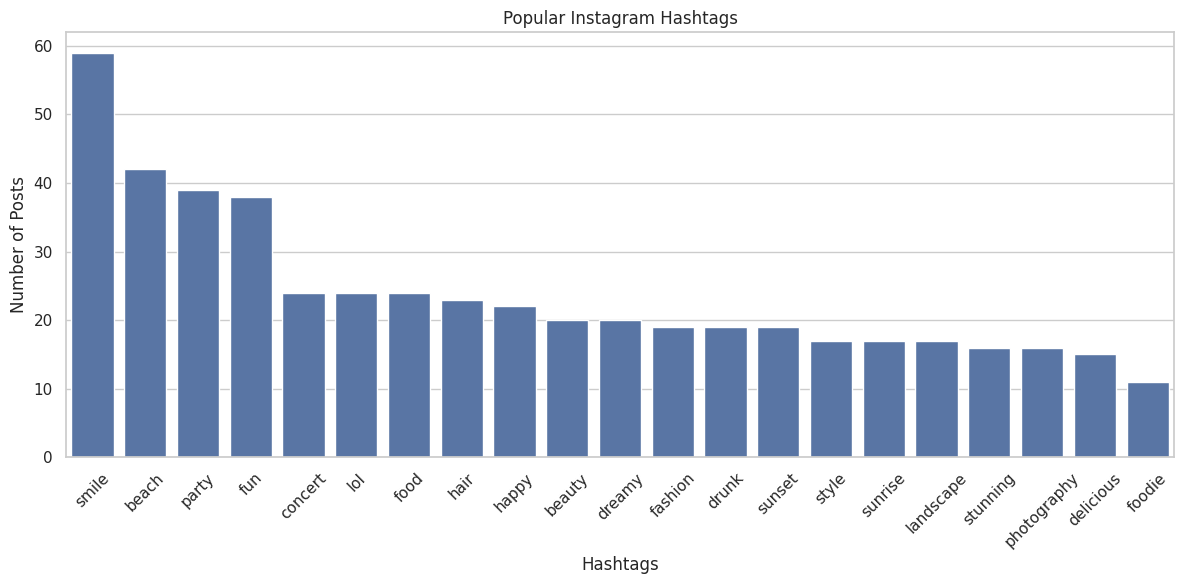

In [43]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=hashtag_analysis,
    x='tag text',
    y='total_posts'
)

plt.title('Popular Instagram Hashtags')
plt.xlabel('Hashtags')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Follower Growth Analysis : This section analyzes follower counts to identify
accounts with higher audience reach.

In [46]:
follower_analysis = (
    follows.groupby('followee ')
    .size()
    .reset_index(name='total_followers')
)

# Add username

follower_analysis = follower_analysis.merge(
    users[['id', 'name']],
    left_on='followee',
    right_on='id',
    how='left'
)

# Sort accounts by followers

follower_analysis = follower_analysis.sort_values(
    by='total_followers',
    ascending=False
)

display(
    follower_analysis[['name', 'total_followers']].head(10)
)

,name,total_followers
0,Kenton_Kirlin,77
24,Tierra.Trantow,77
33,Pearl7,77
6,Kasandra_Homenick,77
28,Jaime53,77
22,Eveline95,77
79,Darby_Herzog,77
76,Donald.Fritsch,77
80,Esther.Zulauf61,77
89,Esmeralda.Mraz57,77


 Conclusion :
 The Instagram engagement analysis was conducted to identify
popular hashtags, content performance and audience engagement.

Key findings:

1. Photo posts received the highest average likes.
2. The #smile hashtag was the most frequently used hashtag.
3. The #dreamy hashtag received the highest average likes.
4. Top accounts recorded 77 followers each.
5. Posting day and time could not be compared because all post
   timestamps were identical.

The analysis provides useful insights for improving
Instagram content planning and audience engagement
for Alfido Tech.